# P1 — Adaptive / Selective Retrieval
## When Does Retrieval Help or Hurt?

**Author:** Sherine Adrou Bakkali — 340396  
**Course:** CS-552 Modern NLP — EPFL, Spring 2026  
**Track:** P1 — Retrieval-stage failure modes

---

This notebook compares three **controlled conditions** on the shared baseline RAG pipeline:

1. **No retrieval** — Mistral answers from parametric knowledge only  
2. **Always retrieve** — standard baseline (Contriever + FAISS + top-k context)  
3. **Selective retrieval** — an LLM router decides per query whether to retrieve

All runs use the same query set, retriever index, generator model, and `evaluate.py` metrics.

**My contribution:** `code/p1_adaptive_routing/` (router, failure labels, pipeline, ablation logging).

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams.update({"figure.dpi": 120, "font.size": 11})

REPO = Path("/scratch/open-project-m2-mnlp212") if Path("/scratch/open-project-m2-mnlp212").exists() else Path("..").resolve()
CODE = REPO / "code"
P1 = CODE / "p1_adaptive_routing"

REPO_RESULTS = REPO / "results" / "p1"
SCRATCH_RESULTS = Path("/scratch/results")
if (REPO_RESULTS / "p1_no_retrieval.json").exists():
    RESULTS_DIR = REPO_RESULTS
elif (SCRATCH_RESULTS / "p1_no_retrieval.json").exists():
    RESULTS_DIR = SCRATCH_RESULTS
else:
    RESULTS_DIR = REPO_RESULTS  # default; load_mode will raise if missing

sys.path.insert(0, str(CODE / "baseline"))
sys.path.insert(0, str(P1))

MODES = ["no_retrieval", "always_retrieve", "selective"]
MODE_LABELS = {
    "no_retrieval": "No retrieval",
    "always_retrieve": "Always retrieve",
    "selective": "Selective",
}

print(f"Repo: {REPO}")
print(f"Results: {RESULTS_DIR}")

Repo: /Users/sherine/Desktop/EPFL/MA2/MNLP Project/open-project-m3-mnlp212
Results: /Users/sherine/Desktop/EPFL/MA2/MNLP Project/open-project-m3-mnlp212/results/p1


## 0 · Environment setup

### Run experiments (cluster only)

Uncomment and run **once** on RCP after the baseline FAISS index exists at `/scratch/faiss_index/baseline`:

```bash
cd code/p1_adaptive_routing
python pipeline_p1.py --mode all --n_questions 100
```

In [2]:
# Uncomment on RCP to run the full ablation (loads Mistral + uses GPU):
# from pipeline_p1 import run_pipeline
# run_pipeline(mode="all", n_questions=100, results_dir=str(RESULTS_DIR))

## 1 · Load results & ablation table

In [3]:
def load_mode(mode):
    path = RESULTS_DIR / f"p1_{mode}.json"
    if not path.exists():
        raise FileNotFoundError(f"Missing {path}. Expected committed files under results/p1/.")
    with open(path) as f:
        return json.load(f)

runs = {m: load_mode(m) for m in MODES}

rows = []
for mode in MODES:
    d = runs[mode]
    m = d["metrics"]
    rows.append({
        "Mode": MODE_LABELS[mode],
        "EM": m["exact_match"],
        "ROUGE-L": m["rouge_l"],
        "Token F1": m["token_f1"],
        "Retrieval hit": m.get("retrieval_hit_rate"),
        "% retrieved": d.get("pct_retrieved", 0.0),
        "n": m["n_samples"],
    })

ablation_df = pd.DataFrame(rows)
ablation_df

,Mode,EM,ROUGE-L,Token F1,Retrieval hit,% retrieved,n
0,No retrieval,0.07,0.2753,0.2814,0.00,0.00,100
1,Always retrieve,0.05,0.1350,0.1308,0.35,1.00,100
2,Selective,0.05,0.1359,0.1317,0.30,0.91,100


## 2 · Metric comparison plot

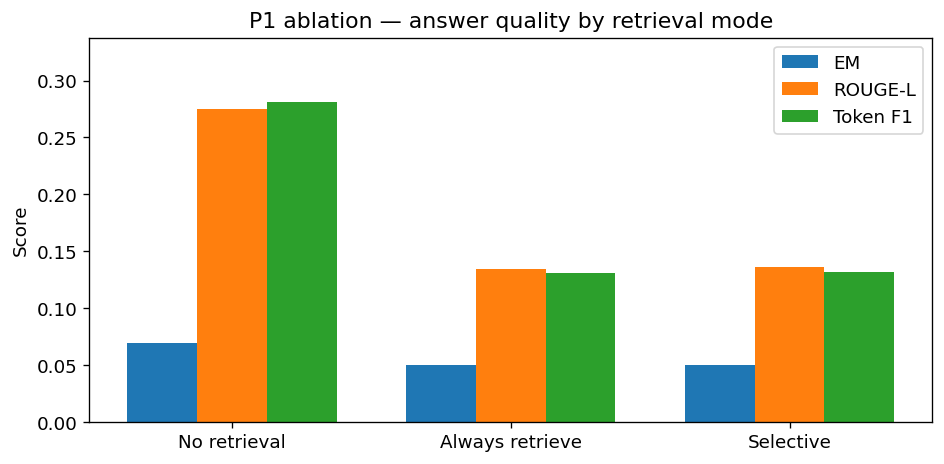

In [4]:
metrics = ["EM", "ROUGE-L", "Token F1"]
x = range(len(MODES))
width = 0.25

fig, ax = plt.subplots(figsize=(8, 4))
for i, metric in enumerate(metrics):
    vals = ablation_df[metric].tolist()
    ax.bar([xi + (i - 1) * width for xi in x], vals, width=width, label=metric)

ax.set_xticks(x)
ax.set_xticklabels([MODE_LABELS[m] for m in MODES])
ax.set_ylabel("Score")
ax.set_title("P1 ablation — answer quality by retrieval mode")
ax.legend()
ax.set_ylim(0, max(ablation_df[metrics].max().max() * 1.2, 0.05))
plt.tight_layout()
plt.show()

## 3 · Failure label distribution (selective mode)

,failure_label,count
0,retrieval_miss,60
1,ignored_evidence,23
2,wrong_skip_decision,9
3,none,5
4,unnecessary_retrieval,3


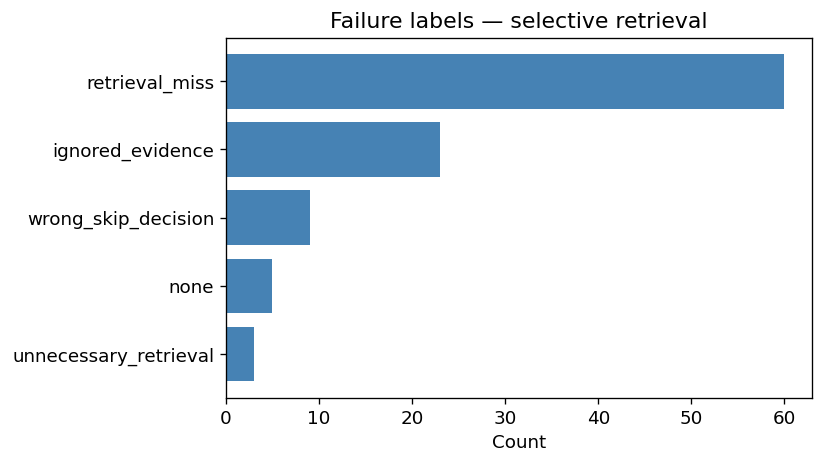

In [5]:
selective = runs["selective"]
label_counts = selective.get("failure_label_counts") or {}
if not label_counts:
    from collections import Counter
    label_counts = Counter(r["failure_label"] for r in selective["results"])

fail_df = pd.DataFrame([
    {"failure_label": k, "count": v}
    for k, v in sorted(label_counts.items(), key=lambda x: -x[1])
])
display(fail_df)

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(fail_df["failure_label"], fail_df["count"], color="steelblue")
ax.set_xlabel("Count")
ax.set_title("Failure labels — selective retrieval")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 4 · Qualitative examples

In [6]:
def examples_for_label(label, n=2):
    rows_out = []
    for r in selective["results"]:
        if r.get("failure_label") == label:
            rows_out.append({
                "failure_label": label,
                "question": r["question"][:80] + "...",
                "gold": r["gold_answers"][0] if r["gold_answers"] else "",
                "retrieved?": r["retrieval_decision"],
                "prediction": r["prediction"][:60],
                "router": (r.get("router_response") or "")[:40],
            })
        if len(rows_out) >= n:
            break
    return rows_out

for label in ["wrong_skip_decision", "unnecessary_retrieval", "retrieval_miss", "ignored_evidence"]:
    ex = examples_for_label(label, n=1)
    if ex:
        print(f"\n=== {label} ===")
        display(pd.DataFrame(ex))


=== wrong_skip_decision ===


,failure_label,question,gold,retrieved?,prediction,router
0,wrong_skip_decision,who had a baby at 100 in the bible...,Sarah,False,There is no record in the Bible of anyone givi...,NO. There is no record in the



=== unnecessary_retrieval ===


,failure_label,question,gold,retrieved?,prediction,router
0,unnecessary_retrieval,who was the ruler of england in 1616...,James I,True,"James VI of Scotland, who was also King of Eng...",YES. The question asks for specific



=== retrieval_miss ===


,failure_label,question,gold,retrieved?,prediction,router
0,retrieval_miss,who wrote he ain't heavy he's my brother lyric...,Bobby Scott,True,"The lyrics for the song ""He Ain't Heavy, He's ...",YES. The answer to this question



=== ignored_evidence ===


,failure_label,question,gold,retrieved?,prediction,router
0,ignored_evidence,when was the last time anyone was on the moon...,14 December 1972 UTC,True,"December 19, 1972",YES. The answer to this question


## 5 · Side-by-side comparison for one query

In [7]:
idx = 0  # change to inspect other queries
comparison = []
for mode in MODES:
    r = runs[mode]["results"][idx]
    comparison.append({
        "mode": MODE_LABELS[mode],
        "retrieval_decision": r["retrieval_decision"],
        "prediction": r["prediction"],
        "exact_match": r["exact_match"],
        "failure_label": r["failure_label"],
    })

print("Question:", runs["selective"]["results"][idx]["question"])
print("Gold:", runs["selective"]["results"][idx]["gold_answers"])
pd.DataFrame(comparison)

Question: when was the last time anyone was on the moon
Gold: ['14 December 1972 UTC', 'December 1972']


,mode,retrieval_decision,prediction,exact_match,failure_label
0,No retrieval,False,"December 14, 2020",0,wrong_skip_decision
1,Always retrieve,True,"December 19, 1972",0,ignored_evidence
2,Selective,True,"December 19, 1972",0,ignored_evidence


## 6 · Summary & individual contribution

**Findings (100 NQ Open validation questions):**

- **No-retrieval beats always-retrieve on EM** (0.07 vs 0.05). With a 35% retrieval hit rate on always-retrieve, retrieved passages often hurt rather than help — noisy context distracts the generator.
- **Selective routing does not improve over always-retrieve.** The LLM router retrieves on 91% of queries (91/100), so metrics are nearly identical (EM 0.05, ROUGE-L 0.14 vs 0.14). The router is too conservative to skip retrieval on knowledge-heavy questions.
- **Failure labels show retrieval is the main bottleneck.** Under selective mode: 60 retrieval misses, 23 ignored evidence, 9 wrong skip decisions, 3 unnecessary retrieval, 5 correct. Routing alone cannot fix low index coverage (aligned with the team baseline hit rate 0.35).
- **Qualitative examples** (see §4–5): wrong skip on “who had a baby at 100 in the bible” (Sarah); ignored evidence on the moon landing date despite a retrieval hit.

**What I implemented:**
- `code/p1_adaptive_routing/pipeline_p1.py` — three-mode ablation on shared baseline
- `router.py` — LLM retrieval router (YES/NO per query)
- `generator_p1.py` — closed-book generation path
- `failure_labels.py` — cross-mode failure taxonomy
- `compare_results.py` — ablation table printer
- This notebook — analysis and qualitative error inspection